# An Open SOTIF Perception Benchmark

**Module 04 · SOTIF (ISO 21448)** · Notebook 6 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/06_sotif_benchmark.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [02 · Triggering conditions and scenarios](02_triggering_conditions_and_scenarios.ipynb); [08-05 · Capstone: AEB from requirement to release](../08_Standards_Regulation_and_Safety_Case/05_capstone_aeb_from_requirement_to_release.ipynb) | ISO 21448:2022, ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Evaluate **any** camera detector against a fixed, versioned SOTIF benchmark in one call, and read the resulting
  triggering-condition report
- Explain each design choice of the benchmark — frame rule, population, matching, conditions, threshold policy —
  and why it has to be fixed **before** a detector is evaluated
- Turn the report into a **verdict against a declared requirement**, a **supported speed per condition** (ODD
  restriction) and a **release decision**, and show how the verdict changes with the requirement
- Compare detectors fairly and recognise when a difference is inside the statistical noise
- State what a benchmark of synthetic conditions on real images can and cannot claim, and how a company would run
  it as a regression gate in CI
- Describe how the LiDAR track on SOTIF-PCOD adds weather and illumination conditions for LiDAR detectors

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety import bench, perturb

import os
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OI = {'blue': '#0072B2', 'orange': '#E69F00', 'green': '#009E73', 'vermillion': '#D55E00',
      'sky': '#56B4E9', 'purple': '#CC79A7', 'yellow': '#F0E442', 'grey': '#999999'}     # Okabe-Ito
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.max_colwidth', 80)
RESULTS = Path('../benchmark/results')
if not RESULTS.exists():                      # Colab: fetch the committed baseline results from GitHub
    import urllib.request
    RESULTS = Path('benchmark_results'); RESULTS.mkdir(exist_ok=True)
    base = 'https://raw.githubusercontent.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/main/benchmark/results/'
    for name in ['fasterrcnn_mobilenet_v3_large_fpn', 'ssdlite320_mobilenet_v3_large']:
        for ext in ('.json', '.objects.csv.gz'):
            urllib.request.urlretrieve(base + name + ext, RESULTS / (name + ext))
print(f"avsafety {avsafety.__version__}; benchmark spec v{bench.SPEC_V1['spec_version']} "
      f"(sha256 {bench.spec_hash(bench.SPEC_V1)[:12]})")

avsafety 1.2.0; benchmark spec v1 (sha256 ecca51391760)


**Data and licence.** The benchmark uses 120 frames of the KITTI object-detection training set (left colour
camera; the Velodyne scan supplies depth for the fog model), fetched on demand by `avsafety.data`. KITTI is licensed
CC BY-NC-SA 3.0 — non-commercial use only — and was recorded in daylight and dry weather around Karlsruhe. The
baselines are COCO-pretrained torchvision detectors that have never seen KITTI. The optional LiDAR track uses the
author's SOTIF-PCOD dataset (IEEE DataPort, doi:10.21227/j43q-z578), which needs a DataPort login.

In [2]:
print(D.attribution('KITTI'))

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


## 1. Why a benchmark, and what it fixes

[Notebook 02](02_triggering_conditions_and_scenarios.ipynb) measured one detector under fog, low light and lens dirt
and turned the result into a triggering-condition table; the [08-05 capstone](../08_Standards_Regulation_and_Safety_Case/05_capstone_aeb_from_requirement_to_release.ipynb)
derived the pedestrian requirement **PR-01** and a release rule. Both were analyses of *one* detector. A
**benchmark** makes the same measurement a reference point: every detector is evaluated on the same frames, under the
same conditions, with the same matching and statistics, so that numbers from different teams can be compared and a
detector update can be checked against its predecessor.

That only works if every choice that could move the numbers is fixed in advance and versioned. `avsafety.bench`
holds the specification (also stored as `benchmark/spec_v1.json`); any change produces a new version, and every
result carries the SHA-256 of the spec it was produced with.

In [3]:
S = bench.SPEC_V1
labels_all = D.kitti_object_labels_all()
assert bench.select_frames(labels_all) == S['frames']        # the frame list follows from the documented rule
sel = labels_all[labels_all['frame'].isin([f'{f:06d}' for f in S['frames']])]
pop = sel[(sel['box_height_px'] >= S['population']['min_height_px']) & (sel['truncated'] <= S['population']['max_truncation'])
          & sel['occluded'].isin(S['population']['occlusion_levels'])]
counts = {c: int(pop['type'].isin(v['kitti']).sum()) for c, v in S['classes'].items()}
summary = pd.DataFrame([
    ('Frames', f"{len(S['frames'])} of {S['frame_rule']['pool_size']} candidate frames; {S['frame_rule']['description']}"),
    ('Evaluated population', f"height >= {S['population']['min_height_px']:.0f} px, truncation <= {S['population']['max_truncation']}, "
                             f"occlusion 0-2: " + ', '.join(f'{k} {v}' for k, v in counts.items())),
    ('Conditions', '; '.join(c['label'] for c in S['conditions'])),
    ('Matching', f"2D IoU >= {S['matching']['iou']}, {S['matching']['order']}; {S['matching']['note']}"),
    ('Threshold policy', S['score_threshold_policy']),
    ('Statistics', f"{S['interval']} intervals at {S['confidence']:.0%}; false positives per frame with exact Poisson intervals"),
], columns=['Element', 'Fixed in spec v1'])
display(summary.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
print(f"Rule reproduced: {len(S['frames'])} frames; {sum(counts.values())} labelled road users in the evaluated population.")

Element,Fixed in spec v1
Frames,"120 of 708 candidate frames; All KITTI object training frames with at least 2 'Pedestrian' labels whose distance sqrt(x^2 + z^2) is <= 40 m form the pool; 120 frames are drawn without replacement with numpy.random.default_rng(21448).choice(pool, 120, replace=False) and sorted."
Evaluated population,"height >= 25 px, truncation <= 0.5, occlusion 0-2: pedestrian 520, cyclist 70, car 213"
Conditions,"clear (original image); fog, V = 200 m; fog, V = 100 m; fog, V = 50 m; fog, V = 25 m; low light, k = 1/64; low light, k = 1/256; lens dirt, 25 % covered"
Matching,"2D IoU >= 0.5, descending score, one-to-one, best IoU among free labels; A detection matched to a label outside the population, overlapping an 'ignore' class (IoU >= 0.5) or covered by a DontCare region (>= 50 % of its area) is neither TP nor FP."
Threshold policy,"One operating threshold for all classes and conditions, declared with the submission before evaluation (default 0.5). Detections with score >= 0.05 are stored so that the report can be recomputed at the declared threshold."
Statistics,clopper-pearson intervals at 95%; false positives per frame with exact Poisson intervals


Rule reproduced: 120 frames; 803 labelled road users in the evaluated population.


Three choices deserve a sentence each.

- **Frames by rule, not by hand.** Frames with at least two pedestrians within 40 m are drawn with a fixed seed.
  Hand-picking would let the benchmark designer — or a submitter — select frames that favour a method. The rule is
  pedestrian-rich on purpose: PR-01 is a pedestrian requirement, and confidence intervals need pedestrians.
- **Ignore regions.** A detection on a *Van* is not a false *car*, and a person on a bicycle is not a false
  *pedestrian*; KITTI's DontCare regions mark unlabelled objects. Counting these as false positives would punish
  correct behaviour.
- **One threshold, declared in advance.** Recall and false positives trade against each other through the score
  threshold. A threshold chosen per condition, or after seeing the results, would turn the benchmark into a tuning
  set. The matching is computed once at a low score (0.05), so the report can be recomputed at the declared
  threshold — but only the declared one is the result.

## 2. The conditions on one frame

Each condition is a function in `avsafety.perturb` with parameters in physical units and its limitations in the
docstring: Koschmieder fog from densified LiDAR depth (visibility $V$ in metres, transmission $e^{-3d/V}$), low
light as a Poisson–Gaussian sensor model (scene light $k$ relative to the original exposure), and defocused lens dirt
(covered fraction). Random elements are seeded per frame, so every detector sees exactly the same pixels.

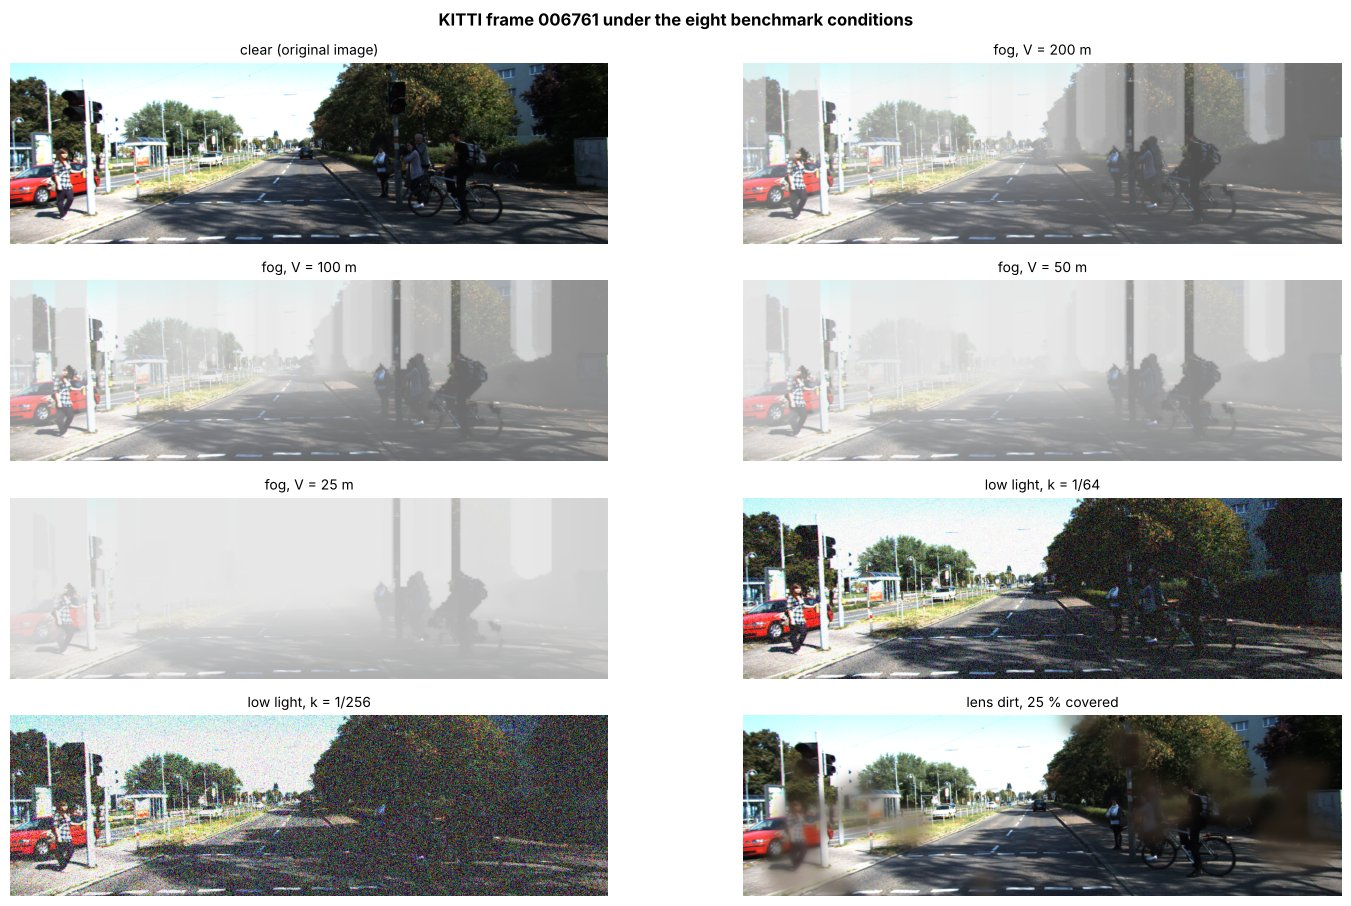

Transmission at V = 50 m for objects at 10, 25, 50 m: 0.55, 0.22, 0.05 — the 5 % at d = V is the definition of meteorological visibility.


In [4]:
SHOW = S['frames'][110]
frame = D.kitti_object(SHOW)
depth = perturb.dense_range(frame)
fig, axes = plt.subplots(4, 2, figsize=(15, 9.2))
for ax, cond in zip(axes.flat, S['conditions']):
    img, _ = bench.apply_condition(frame, cond, depth)
    ax.imshow(img); ax.set_title(cond['label'], fontsize=10); ax.axis('off')
plt.suptitle(f'KITTI frame {SHOW:06d} under the eight benchmark conditions', fontweight='bold')
plt.tight_layout(); plt.show()
t = perturb.transmission(np.array([10, 25, 50]), 50)
print("Transmission at V = 50 m for objects at 10, 25, 50 m: " + ", ".join(f"{x:.2f}" for x in t)
      + " — the 5 % at d = V is the definition of meteorological visibility.")

## 3. Evaluate your own detector in one cell

A detector is any Python callable that takes an RGB image (`H x W x 3`, `uint8`) and returns
`(box_xyxy, score, label)` tuples with labels `pedestrian`, `cyclist` or `car`. The cell below wraps a torchvision
model, but anything with that signature works — an ONNX runtime session, a TensorRT engine behind a socket, or a
production detector's Python binding. Replace `my_detector` with yours.

A full run (120 frames × 8 conditions = 960 detector calls) takes about 9 minutes on two idle CPU threads for Faster R-CNN (MobileNetV3) and about 6 minutes for SSDlite;
to keep the notebook quick, the cell evaluates the first 12 frames (marked *not official*), and Section 4 reads the
committed full results instead. Set `FULL_RUN = True` to run everything, or use the command line:
`python -m avsafety.bench --callable my_module:my_detector --out my_result.json`.

In [5]:
import torch
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
torch.set_num_threads(2)
_model = ssdlite320_mobilenet_v3_large(weights='DEFAULT', score_thresh=0.05).eval()

def my_detector(image):
    # Benchmark API: RGB uint8 image -> [((x1, y1, x2, y2), score, label), ...]
    x = torch.from_numpy(np.array(image, dtype=np.uint8)).permute(2, 0, 1).float() / 255
    with torch.inference_mode():
        out = _model([x])[0]
    return bench.coco_to_bench(out['boxes'].numpy(), out['scores'].numpy(), out['labels'].numpy())

FULL_RUN = False
t0 = time.time()
mine = bench.evaluate(my_detector, frames=None if FULL_RUN else S['frames'][:12], threshold=0.5,
                      submission={'name': 'my detector (SSDlite, COCO)', 'model': 'ssdlite320_mobilenet_v3_large',
                                  'weights': 'torchvision COCO_V1', 'training_data': 'COCO 2017 train',
                                  'date': '2026-10-29'})
print(f"{mine.run['n_frames']} frames x {len(mine.run['conditions'])} conditions in {time.time() - t0:.0f} s; "
      f"official run: {mine.run['official']}")
rel = mine.release('PR-01')
print(f"Release verdict against PR-01 on this subset: {rel['verdict']}")

12 frames x 8 conditions in 13 s; official run: False
Release verdict against PR-01 on this subset: DO NOT RELEASE


## 4. Reading the report

The committed baseline results contain the per-object outcomes of full runs, so any table can be recomputed — at
the declared threshold, against any requirement — without running the detector again. We read the result of
`fasterrcnn_mobilenet_v3_large_fpn`, the detector used in Notebook 02 and the capstone.

In [6]:
def load(name):
    return bench.Report.load(RESULTS / f'{name}.objects.csv.gz', RESULTS / f'{name}.json')

frcnn = load('fasterrcnn_mobilenet_v3_large_fpn')
labels = {c['id']: c['label'] for c in S['conditions']}
bc = pd.DataFrame(frcnn.by_condition())
bc['condition'] = bc['condition'].map(labels)
tab = bc.pivot(index='condition', columns='class', values='recall').reindex(labels.values())[['pedestrian', 'cyclist', 'car']]
tab['pedestrian FP/frame'] = bc[bc['class'] == 'pedestrian'].set_index('condition')['fp_per_frame']
display(tab.style.format('{:.2f}'))
print(f"Threshold {frcnn.threshold}; {frcnn.n_frames} frames; n per condition: "
      + ", ".join(f"{c} {int(bc[(bc['class'] == c)]['n'].iloc[0])}" for c in ['pedestrian', 'cyclist', 'car']))

class,pedestrian,cyclist,car,pedestrian FP/frame
condition,,,,
clear (original image),0.43,0.43,0.77,1.23
"fog, V = 200 m",0.42,0.23,0.53,1.30
"fog, V = 100 m",0.40,0.17,0.46,1.33
"fog, V = 50 m",0.41,0.14,0.39,1.28
"fog, V = 25 m",0.37,0.06,0.28,1.36
"low light, k = 1/64",0.27,0.10,0.39,1.06
"low light, k = 1/256",0.13,0.04,0.23,0.64
"lens dirt, 25 % covered",0.38,0.34,0.70,1.20


Threshold 0.5; 120 frames; n per condition: pedestrian 520, cyclist 70, car 213


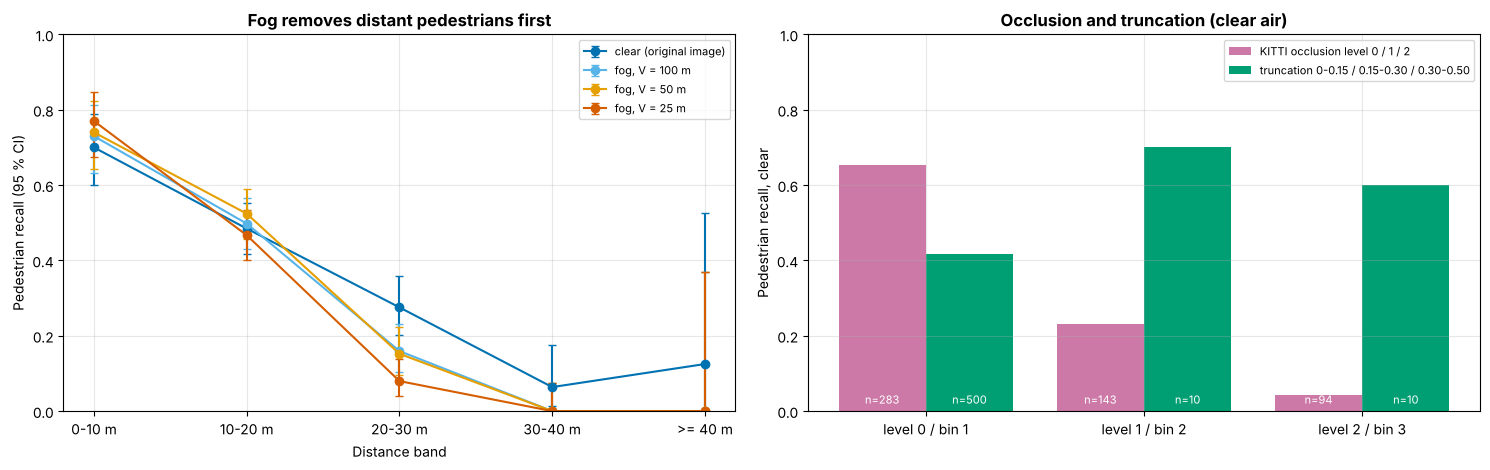

Lens dirt: pedestrian recall 0.42 outside the dirty area (n = 394) vs 0.28 behind it (n = 126).
Clear air: recall 0.70 at 0-10 m vs 0.12 at >= 40 m.


In [7]:
bd = pd.DataFrame(frcnn.by_distance())
bd = bd[bd['class'] == 'pedestrian']
bands = [b for b in dict.fromkeys(bd['band'])]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
for cid, col in zip(['clear', 'fog_100', 'fog_50', 'fog_25'], [OI['blue'], OI['sky'], OI['orange'], OI['vermillion']]):
    g = bd[bd['condition'] == cid].set_index('band').loc[bands]
    ax1.errorbar(np.arange(len(bands)), g['recall'], yerr=[g['recall'] - g['ci_low'], g['ci_high'] - g['recall']],
                 fmt='o-', capsize=3, color=col, label=labels[cid])
ax1.set_xticks(range(len(bands)), bands); ax1.set_xlabel('Distance band'); ax1.set_ylabel('Pedestrian recall (95 % CI)')
ax1.set_ylim(0, 1); ax1.legend(fontsize=8); ax1.set_title('Fog removes distant pedestrians first', fontweight='bold')
occ = pd.DataFrame(frcnn.by_occlusion()); occ = occ[occ['class'] == 'pedestrian']
tr = pd.DataFrame(frcnn.by_truncation()); tr = tr[tr['class'] == 'pedestrian']
x = np.arange(3)
ax2.bar(x - 0.2, occ['recall'], 0.4, color=OI['purple'], label='KITTI occlusion level 0 / 1 / 2')
ax2.bar(x + 0.2, tr['recall'], 0.4, color=OI['green'], label='truncation 0-0.15 / 0.15-0.30 / 0.30-0.50')
for xi, (a, b) in enumerate(zip(occ['n'], tr['n'])):
    ax2.text(xi - 0.2, 0.02, f'n={a}', ha='center', fontsize=8, color='white')
    ax2.text(xi + 0.2, 0.02, f'n={b}', ha='center', fontsize=8, color='white')
ax2.set_xticks(x, ['level 0 / bin 1', 'level 1 / bin 2', 'level 2 / bin 3']); ax2.set_ylim(0, 1)
ax2.set_ylabel('Pedestrian recall, clear'); ax2.legend(fontsize=8); ax2.set_title('Occlusion and truncation (clear air)', fontweight='bold')
plt.tight_layout(); plt.show()
dirt = pd.DataFrame(frcnn.lens_dirt_split()); dirt = dirt[dirt['class'] == 'pedestrian'].set_index('where')
print(f"Lens dirt: pedestrian recall {dirt.loc['outside dirt', 'recall']:.2f} outside the dirty area "
      f"(n = {dirt.loc['outside dirt', 'n']}) vs {dirt.loc['behind dirt', 'recall']:.2f} behind it (n = {dirt.loc['behind dirt', 'n']}).")
near = bd[(bd['condition'] == 'clear')].set_index('band')
print(f"Clear air: recall {near['recall'].iloc[0]:.2f} at {bands[0]} vs {near['recall'].iloc[-1]:.2f} at {bands[-1]}.")

Read the tables the way an assessor would. Recall falls with visibility and with distance — the fog model
removes contrast as $e^{-3d/V}$ — and it falls sharply for largely occluded pedestrians even in clear air:
occlusion is a triggering condition that no ODD restriction can remove in urban traffic. Low light hurts this
detector more than any fog level tested, and cars and cyclists suffer more from fog than pedestrians (larger share of
distant objects). The lens-dirt average hides the real effect: a pedestrian behind a dirt blob is a different case
from one beside it, which is why the report splits them.

## 5. Verdict, supported speed and release — the requirement is a parameter

The triggering-condition table applies a declared **requirement**. The default is PR-01 from the capstone; the
65 % requirement of Notebook 02 is available as `TC-04-02`, and any other can be passed as a
`bench.Requirement` or a JSON file. For each condition the report gives the recall in the requirement's scope,
the one-sided confidence bound, a verdict, and the **highest speed whose stopping distance the evidence covers** —
the ODD restriction that would make the requirement hold.

In [8]:
def tc_table(report, req):
    t = pd.DataFrame(report.triggering_conditions(req))
    return t[['label', 'in_odd', 'n', 'recall', 'lower_bound', 'verdict', 'v_max_kmh', 'measure']].rename(
        columns={'label': 'condition', 'in_odd': 'in ODD', 'lower_bound': 'one-sided lower bound',
                 'v_max_kmh': 'supported speed (km/h)'})

pr01 = bench.REQUIREMENTS['PR-01']
print(f"PR-01: recall >= {pr01.min_recall} ({pr01.confidence:.0%} one-sided) within {pr01.range_m():.1f} m "
      f"(stopping distance at {pr01.max_speed_kmh:.0f} km/h); ODD conditions: {', '.join(pr01.odd_conditions)}")
display(tc_table(frcnn, pr01).style.format({'recall': '{:.2f}', 'one-sided lower bound': '{:.2f}',
                                            'supported speed (km/h)': '{:.0f}'}, na_rep='none').hide(axis='index'))
for name in ['PR-01', 'TC-04-02']:
    r = frcnn.release(name)
    print(f"{name}: {r['verdict']}; supported speed per ODD condition: {r['restricted_odd_kmh']}")

PR-01: recall >= 0.9 (95% one-sided) within 33.1 m (stopping distance at 60 km/h); ODD conditions: clear, low_light_64


condition,in ODD,n,recall,one-sided lower bound,verdict,supported speed (km/h),measure
clear (original image),True,246,0.58,0.53,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"fog, V = 200 m",False,246,0.60,0.55,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"fog, V = 100 m",False,246,0.59,0.54,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"fog, V = 50 m",False,246,0.60,0.55,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"fog, V = 25 m",False,246,0.55,0.49,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"low light, k = 1/64",True,246,0.40,0.35,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"low light, k = 1/256",False,246,0.23,0.18,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design
"lens dirt, 25 % covered",False,246,0.54,0.49,does not meet,none,exclude condition from the ODD (needs an ODD monitor) or improve the design


PR-01: DO NOT RELEASE; supported speed per ODD condition: {'clear': None, 'low_light_64': None}


TC-04-02: RELEASE WITH ODD RESTRICTION; supported speed per ODD condition: {'clear': 35, 'low_light_64': None}


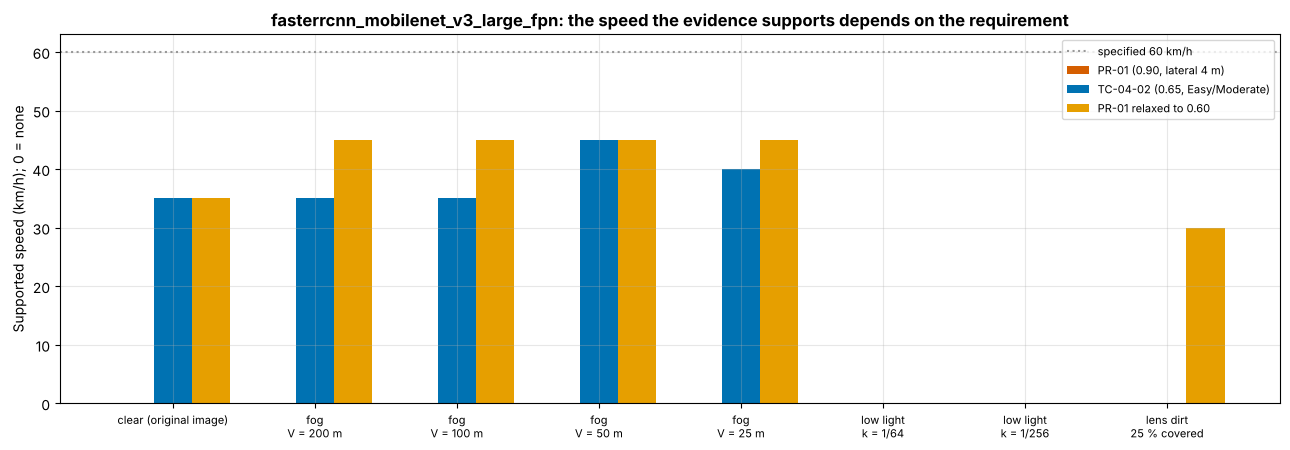

Against TC-04-02 the clear-air evidence supports 35 km/h and fog at V = 25 m 40 km/h; against PR-01 clear air supports no speed.


In [9]:
reqs = {'PR-01 (0.90, lateral 4 m)': bench.REQUIREMENTS['PR-01'], 'TC-04-02 (0.65, Easy/Moderate)': bench.REQUIREMENTS['TC-04-02'],
        'PR-01 relaxed to 0.60': bench.Requirement(id='PR-01-0.60', min_recall=0.60)}
fig, ax = plt.subplots(figsize=(13, 4.6))
ids = [c['id'] for c in S['conditions']]
for k, ((name, req), col) in enumerate(zip(reqs.items(), [OI['vermillion'], OI['blue'], OI['orange']])):
    t = pd.DataFrame(frcnn.triggering_conditions(req)).set_index('condition').loc[ids]
    ax.bar(np.arange(len(ids)) + (k - 1) * 0.27, t['v_max_kmh'].fillna(0), 0.27, color=col, label=name)
ax.axhline(60, color=OI['grey'], ls=':', label='specified 60 km/h')
ax.set_xticks(range(len(ids)), [labels[i].replace(', ', '\n') for i in ids], fontsize=8)
ax.set_ylabel('Supported speed (km/h); 0 = none'); ax.legend(fontsize=8, loc='upper right')
ax.set_title('fasterrcnn_mobilenet_v3_large_fpn: the speed the evidence supports depends on the requirement', fontweight='bold')
plt.tight_layout(); plt.show()
t2 = pd.DataFrame(frcnn.triggering_conditions('TC-04-02')).set_index('condition')
fmt = lambda v: 'no speed' if v is None or pd.isna(v) else f'{v:.0f} km/h'
t1 = pd.DataFrame(frcnn.triggering_conditions('PR-01')).set_index('condition')
print(f"Against TC-04-02 the clear-air evidence supports {fmt(t2.loc['clear', 'v_max_kmh'])} and fog at V = 25 m "
      f"{fmt(t2.loc['fog_25', 'v_max_kmh'])}; against PR-01 clear air supports {fmt(t1.loc['clear', 'v_max_kmh'])}.")

The same measurement gives three different decisions under three requirements — which is the point of
declaring the requirement **before** the test and recording it in the result. Two details of the logic matter:

- A lower speed shortens the braking-relevant range, so fewer and nearer pedestrians are in scope. Near
  pedestrians are detected better, but the sample shrinks, and with fewer than 29 pedestrians even a perfect
  detector cannot show 0.90 at 95 % confidence (zero-failure bound $0.05^{1/n}$). "No supported speed" can therefore
  mean *insufficient evidence* as much as *insufficient performance*; the verdict column tells which.
- Supported speeds of neighbouring conditions can differ by a grid step in either direction; here even dense fog
  (V = 25–50 m) supports a higher speed than clear air, because near-range recall in fog is slightly higher (Section 4, inside the
  intervals). Differences of one grid step are sampling noise at the boundary, not evidence that fog helps; the
  boundary is a bracket, as in Notebook 02.
- Conditions outside the declared ODD (fog, very low light, dirt) do not block a release, but each one that is not
  met needs a monitor that detects it at runtime — visibility estimation, illumination, blockage detection — and a
  defined degradation. That is the ODD restriction of ISO 21448 clause 8 in executable form.

## 6. Comparing detectors

A benchmark invites ranking. The question a SOTIF engineer asks is narrower: *is the difference larger than the
uncertainty, and does it change a verdict?*

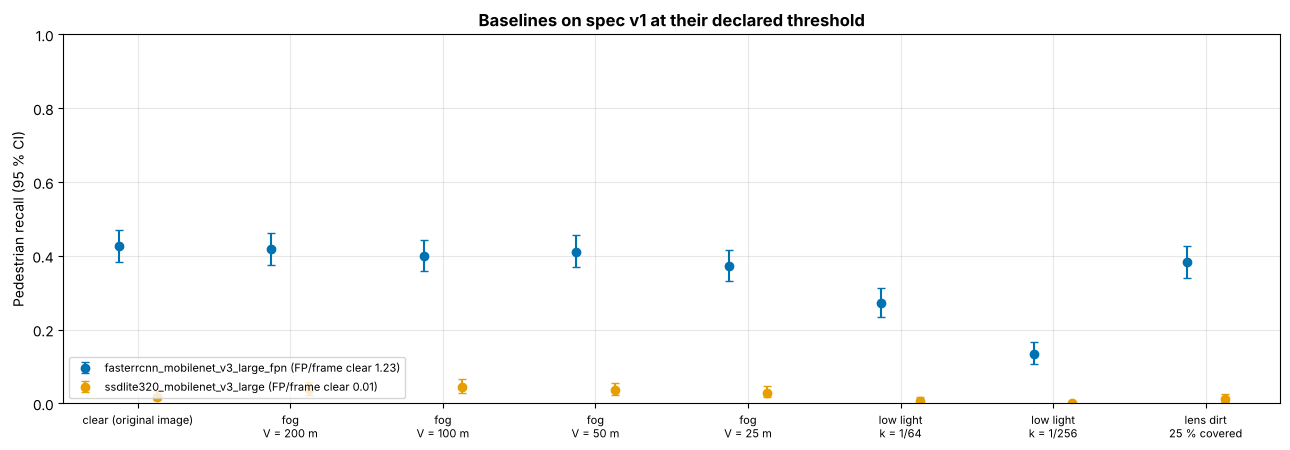

detector,threshold,PR-01,TC-04-02,"TC-04-02 speed, clear","TC-04-02 speed, fog 50 m"
fasterrcnn_mobilenet_v3_large_fpn,0.50,DO NOT RELEASE,RELEASE WITH ODD RESTRICTION,35,45
ssdlite320_mobilenet_v3_large,0.50,DO NOT RELEASE,DO NOT RELEASE,none,none


In [10]:
names = sorted(p.name.replace('.objects.csv.gz', '') for p in RESULTS.glob('*.objects.csv.gz'))
reports = {n: load(n) for n in names}
fig, ax = plt.subplots(figsize=(13, 4.6))
for k, (n, rep) in enumerate(reports.items()):
    d = pd.DataFrame(rep.by_condition()); d = d[d['class'] == 'pedestrian'].set_index('condition').loc[ids]
    x = np.arange(len(ids)) + (k - (len(reports) - 1) / 2) * 0.25
    ax.errorbar(x, d['recall'], yerr=[d['recall'] - d['ci_low'], d['ci_high'] - d['recall']], fmt='o', capsize=3,
                color=[OI['blue'], OI['orange'], OI['green']][k % 3], label=f"{n} (FP/frame clear {d.loc['clear', 'fp_per_frame']:.2f})")
ax.set_xticks(range(len(ids)), [labels[i].replace(', ', '\n') for i in ids], fontsize=8); ax.set_ylim(0, 1)
ax.set_ylabel('Pedestrian recall (95 % CI)'); ax.legend(fontsize=8, loc='lower left')
ax.set_title('Baselines on spec v1 at their declared threshold', fontweight='bold')
plt.tight_layout(); plt.show()
rows = []
for n, rep in reports.items():
    tc = {r['condition']: r for r in rep.triggering_conditions('TC-04-02')}
    rows.append({'detector': n, 'threshold': rep.threshold, 'PR-01': rep.release('PR-01')['verdict'],
                 'TC-04-02': rep.release('TC-04-02')['verdict'],
                 'TC-04-02 speed, clear': tc['clear']['v_max_kmh'], 'TC-04-02 speed, fog 50 m': tc['fog_50']['v_max_kmh']})
display(pd.DataFrame(rows).style.hide(axis='index').format({'threshold': '{:.2f}', 'TC-04-02 speed, clear': '{:.0f}', 'TC-04-02 speed, fog 50 m': '{:.0f}'}, na_rep='none'))

In [11]:
def threshold_sweep(rep, taus=(0.3, 0.4, 0.5, 0.6, 0.7)):
    out = []
    for tau in taus:
        r = bench.Report(objects=rep.objects, spec=rep.spec, submission={**rep.submission, 'score_threshold': tau}, run=rep.run)
        c = {(x['condition'], x['class']): x for x in r.by_condition()}
        out.append({'tau': tau, 'recall clear': c[('clear', 'pedestrian')]['recall'],
                    'FP/frame clear': c[('clear', 'pedestrian')]['fp_per_frame'],
                    'recall fog 25 m': c[('fog_25', 'pedestrian')]['recall']})
    return pd.DataFrame(out)

sweep = threshold_sweep(frcnn)
display(sweep.style.hide(axis='index').format(precision=2))
print(f"Lowering the threshold from 0.5 to 0.3 raises clear-air pedestrian recall by "
      f"{sweep.set_index('tau').loc[0.3, 'recall clear'] - sweep.set_index('tau').loc[0.5, 'recall clear']:+.2f} "
      f"and false positives by {sweep.set_index('tau').loc[0.3, 'FP/frame clear'] - sweep.set_index('tau').loc[0.5, 'FP/frame clear']:+.2f} per frame. "
      "Picking the threshold after seeing this table is exactly what the threshold policy forbids.")

tau,recall clear,FP/frame clear,recall fog 25 m
0.30,0.47,2.82,0.41
0.40,0.46,1.87,0.39
0.50,0.43,1.23,0.37
0.60,0.41,0.88,0.36
0.70,0.39,0.52,0.33


Lowering the threshold from 0.5 to 0.3 raises clear-air pedestrian recall by +0.05 and false positives by +1.59 per frame. Picking the threshold after seeing this table is exactly what the threshold policy forbids.


The SSDlite baseline barely registers at its declared threshold of 0.5. Its input is resized to 320 × 320 pixels,
so a pedestrian 30 m away covers only a few pixels, and its scores are generally lower than those of Faster R-CNN:
at a threshold of 0.1 the same model finds about a third of the pedestrians, at the cost of dozens of false
positives per frame. That is the threshold policy at work — the
threshold is part of the submitted system, and choosing it after seeing the result is not allowed.

Two observations carry over to any comparison. First, overlapping intervals are common at this sample
size: with about 500 pedestrians per condition a difference of a few percentage points is not established, and
for the PR-01 scope (about 250 pedestrians) even less. Second, recall is bought with false positives — and in the
AEB item the false positive is the **ASIL D** hazard (unintended braking, SG-01), so a detector that wins on recall
by lowering its threshold may lose the safety argument elsewhere. A leaderboard sorted by one number hides this;
the report keeps both.

## 7. What the benchmark can and cannot claim

| It can show | It cannot show |
|---|---|
| How a detector degrades under **documented models** of fog, low light and dirt, on real images and real labels | How it behaves in **real** fog, night or rain — KITTI has none; the models omit scattering blur, headlights, glare, droplets |
| Per-frame recall with honest intervals for the sampling of labels | Independence: 120 frames contain repeated scenes; the frames are from one city, one camera, one season |
| Comparisons at a declared threshold between detectors evaluated identically | Performance of a KITTI-trained detector unless it provably excluded these frames |
| Whether a declared requirement is met, with what speed restriction | Vehicle-level safety: tracking, radar fusion, the braking decision and controllability are outside the component |

**Class mapping.** COCO has no *cyclist* and no KITTI *Van*. The baselines map person → pedestrian, car and truck
→ car, and fuse a person over a bicycle into a cyclist. A detector trained on KITTI classes avoids this loss; the
mapping is part of the submitted system and has to be reported.

**Sample size.** How many pedestrians would a test need to *demonstrate* PR-01, if the detector's true recall were
a given value? The cell computes the smallest $n$ for which the expected outcome passes.

In [12]:
def n_needed(true_recall, target=0.90, conf=0.95, n_max=5000):
    # Smallest n for which observing round(true_recall * n) detections gives a one-sided lower bound >= target.
    for n in range(10, n_max):
        if bench.verdict(int(np.floor(true_recall * n)), n, target, conf) == 'meets':
            return n
    return None

need = pd.DataFrame({'true recall': [0.92, 0.95, 0.98, 1.0]})
need['pedestrians needed for PR-01'] = [n_needed(p) for p in need['true recall']]
display(need.style.hide(axis='index').format({'true recall': '{:.2f}'}))
n_scope = pd.DataFrame(frcnn.triggering_conditions('PR-01')).set_index('condition').loc['clear', 'n']
print(f"Spec v1 has {n_scope} pedestrians in the PR-01 scope per condition: enough to demonstrate PR-01 only for a "
      "detector whose true recall is about 0.95 or better; a real campaign needs thousands of labelled instances.")

true recall,pedestrians needed for PR-01
0.92,649
0.95,116
0.98,46
1.00,29


Spec v1 has 246 pedestrians in the PR-01 scope per condition: enough to demonstrate PR-01 only for a detector whose true recall is about 0.95 or better; a real campaign needs thousands of labelled instances.


## 8. Running it as a regression gate in CI

In a company the benchmark runs on every candidate model, not once. The pattern below compares a candidate with
the released model condition by condition and fails the pipeline if a verdict gets worse or a recall drops by more
than the noise allows. Here the "released" model is `fasterrcnn_mobilenet_v3_large_fpn` and the "candidate" is the
smaller `ssdlite320_mobilenet_v3_large` — a typical cost-down change.

In [13]:
ORDER = {'meets': 2, 'inconclusive': 1, 'does not meet': 0, 'no data': 0}

def regression_gate(released, candidate, requirement='TC-04-02', conf=0.95):
    # Fail if a verdict worsens, or if the candidate's recall upper bound lies below the released recall.
    old = {r['condition']: r for r in released.triggering_conditions(requirement)}
    findings = []
    for r in candidate.triggering_conditions(requirement):
        o = old[r['condition']]
        hi = bench.binomial_interval(r['detected'], r['n'], conf, sides=1)[1]
        if ORDER[r['verdict']] < ORDER[o['verdict']]:
            findings.append((r['label'], f"verdict {o['verdict']} -> {r['verdict']}"))
        elif r['n'] and o['recall'] is not None and hi < o['recall']:
            findings.append((r['label'], f"recall {o['recall']:.2f} -> {r['recall']:.2f} (upper bound {hi:.2f})"))
    return findings

released, candidate = reports['fasterrcnn_mobilenet_v3_large_fpn'], reports['ssdlite320_mobilenet_v3_large']
findings = regression_gate(released, candidate)
print("GATE FAILED" if findings else "GATE PASSED", f"({len(findings)} regression(s) against TC-04-02)")
for cond, why in findings:
    print(f"  {cond}: {why}")

GATE FAILED (8 regression(s) against TC-04-02)
  clear (original image): recall 0.55 -> 0.02 (upper bound 0.03)
  fog, V = 200 m: recall 0.55 -> 0.04 (upper bound 0.06)
  fog, V = 100 m: recall 0.52 -> 0.05 (upper bound 0.07)
  fog, V = 50 m: recall 0.54 -> 0.04 (upper bound 0.06)
  fog, V = 25 m: recall 0.49 -> 0.03 (upper bound 0.05)
  low light, k = 1/64: recall 0.35 -> 0.01 (upper bound 0.02)
  low light, k = 1/256: recall 0.17 -> 0.00 (upper bound 0.01)
  lens dirt, 25 % covered: recall 0.49 -> 0.01 (upper bound 0.02)


In a pipeline the same check is a job that runs `python -m avsafety.bench --callable ... --out candidate.json`
and then a script like `regression_gate`, storing both JSON files as build artefacts. The repository's own
`.github/workflows/benchmark.yml` is the manually triggered version: it evaluates a model on a GitHub-hosted runner
and attaches the Markdown report to the run summary. Three practices make the gate trustworthy: the spec hash is
checked (no silent change of frames or conditions), the threshold is part of the model release (not a pipeline
parameter), and the result files are kept as **evidence with a version** — the SOTIF argument cites
`result.json` of the released model, not a number in a slide.

## 9. The LiDAR track and SOTIF-PCOD

KITTI cannot provide real adverse weather for LiDAR either. **SOTIF-PCOD** (Patel, IEEE DataPort, 2024) contains 547
LiDAR frames in KITTI format generated in CARLA for a highway lane-change scenario under 21 weather presets — clear,
cloudy, wet, wet-cloudy, soft, mid and hard rain at noon, sunset and night (Patel & Jung, VEHITS 2024). It adds
conditions the camera track cannot: the simulator renders the weather into the point cloud instead of a model
applied afterwards, at the price of a simulation-to-reality gap that the VEHITS paper measured for KITTI-trained
detectors.

`bench.evaluate_lidar` evaluates any point-cloud detector on a KITTI-format folder and groups the frames by
condition (a CARLA preset in the folder name, or a CSV). Matching uses the bird's-eye-view centre distance
(≤ 2 m), as in the nuScenes detection metric. Below, the same code runs on 40 benchmark frames written as a
KITTI-format folder, once as recorded and once with the LiDAR fog model of `perturb.lidar_fog` at $V$ = 25 m,
with the non-learned clustering baseline `bench.lidar_cluster_baseline`. If `SOTIF_PCOD_DIR` is set, the last
lines evaluate the same baseline on SOTIF-PCOD.

In [14]:
import csv
tmp = Path(tempfile.mkdtemp(prefix='kitti_fmt_'))
rows = []
for cid, vis in [('clear', np.inf), ('lidar_fog_25', 25.0)]:
    base = tmp / cid / 'training'
    for sub in ('velodyne', 'label_2', 'calib'):
        (base / sub).mkdir(parents=True, exist_ok=True)
    for f in S['frames'][:40]:
        fr = D.kitti_object(f, parts=('points',))
        perturb.lidar_fog(fr.points, vis).astype(np.float32).tofile(base / 'velodyne' / f'{f:06d}.bin')
        for sub, archive in (('label_2', 'data_object_label_2.zip'), ('calib', 'data_object_calib.zip')):
            (base / sub / f'{f:06d}.txt').write_bytes(D.fetch_kitti_file(archive, f'training/{sub}/{f:06d}.txt'))
        rows.append({'frame': f'{cid}/training/velodyne/{f:06d}.bin', 'condition': cid})
with open(tmp / 'conditions.csv', 'w', newline='') as fh:
    w = csv.DictWriter(fh, ['frame', 'condition']); w.writeheader(); w.writerows(rows)

t0 = time.time()
lidar = bench.evaluate_lidar(bench.lidar_cluster_baseline, tmp, conditions_csv=tmp / 'conditions.csv', threshold=0.2,
                             max_azimuth_deg=40)   # KITTI labels exist only inside the camera's field of view
lt = pd.DataFrame(lidar['results'])
display(lt[lt['class'] != 'cyclist'].style.hide(axis='index').format(precision=2))
print(f"{sum(lidar['frames_per_condition'].values())} LiDAR frames in {time.time() - t0:.0f} s; matching: {lidar['matching']}.")

if os.environ.get('SOTIF_PCOD_DIR'):
    pcod = bench.evaluate_lidar(bench.lidar_cluster_baseline, threshold=0.2)
    display(pd.DataFrame(pcod['results']))
else:
    print("SOTIF_PCOD_DIR is not set: download SOTIF-PCOD from IEEE DataPort (doi:10.21227/j43q-z578), extract it and "
          "set the variable to evaluate LiDAR detectors per weather preset. The loader follows the documented KITTI "
          "layout and has not yet been run on the released archive.")
import shutil
shutil.rmtree(tmp, ignore_errors=True)

condition,class,n,detected,recall,ci_low,ci_high,fp_per_frame
clear,car,99,50,0.51,0.40,0.61,2.20
clear,pedestrian,202,71,0.35,0.29,0.42,4.85
lidar_fog_25,car,99,6,0.06,0.02,0.13,0.38
lidar_fog_25,pedestrian,202,36,0.18,0.13,0.24,1.05


80 LiDAR frames in 2 s; matching: BEV centre distance <= 2.0 m, greedy by score.
SOTIF_PCOD_DIR is not set: download SOTIF-PCOD from IEEE DataPort (doi:10.21227/j43q-z578), extract it and set the variable to evaluate LiDAR detectors per weather preset. The loader follows the documented KITTI layout and has not yet been run on the released archive.


The clustering baseline is deliberately weak: it is a floor that shows the pipeline works on real KITTI
scans (and how a LiDAR condition shifts it), not a competitor. A learned detector from OpenPCDet or MMDetection3D
plugs in through the same callable signature.

## In industry

**Work product.** The benchmark report is evidence for the *SOTIF verification and validation* work products
(ISO 21448 clauses 9–10): the measured performance of the perception component under known triggering conditions
(Area 2), the derived ODD restriction for the function specification (clause 8), and — kept per model version —
the regression evidence that a software update has not reopened a closed triggering condition. The result JSON is
an entry in the safety case's evidence register; ISO/PAS 8800 asks for the same kind of data-set and performance
evidence for AI components.

**Who produces it.** The perception team runs it for every release candidate (often nightly); the SOTIF engineer
owns the spec — frames, conditions, requirement, decision rule — and its versioning; the safety assessor reviews the
spec once and the results per release. Changing the spec is a change request, not a pull request in the model repo.

**What reviewers and assessors check.**

- [ ] Spec versioned and hashed; frame selection by rule; no overlap with training or tuning data (declared and checked)
- [ ] Requirement, confidence level and threshold fixed **before** evaluation and recorded in the result
- [ ] Synthetic conditions documented with physics, parameters in units, limitations, and a plan to validate them against real data
- [ ] Intervals and sample sizes reported; "inconclusive" kept apart from "met"; frames not treated as independent encounters
- [ ] False positives reported next to recall (unintended braking is the ASIL D hazard of the AEB item)
- [ ] Class mapping and ignore rules stated; per-object outcomes archived so the analysis can be re-run
- [ ] Regression gate in CI with the released model as reference; results stored as versioned evidence

## Key takeaways

- A benchmark turns a one-off triggering-condition analysis into a **reference point**: same frames, same
  conditions, same matching, same statistics — fixed in a versioned, hashed spec.
- The report answers SOTIF questions directly: recall per condition with intervals, a verdict against a **declared
  requirement**, the **speed the evidence supports** per condition, and a release verdict by a stated rule.
- The requirement is a parameter, and changing it changes the decision; that is why it is declared before the test.
- Differences between detectors are only meaningful beyond the confidence intervals, and recall must always be read
  with false positives.
- Synthetic fog and low light on real images are models: good for ranking under documented conditions, not a
  substitute for real-condition data. SOTIF-PCOD adds simulated weather for LiDAR, with its own simulation gap.
- In CI, the benchmark becomes a regression gate whose JSON results are safety-case evidence for each model version.

## Self-assessment

1. Why is the frame list derived from a rule and a seed rather than chosen by hand?
2. A detection overlaps a KITTI *Van* with IoU 0.8 and is labelled *car*. Is it a false positive in this benchmark? Why?
3. A detector meets PR-01 in clear air only up to 30 km/h. What does the release rule decide, and what must the
   function specification then contain?
4. Detector A has clear-air pedestrian recall 0.74 [0.70, 0.78], detector B 0.76 [0.72, 0.80]. Is B better?
5. A team reports a result at threshold 0.35, chosen because it gave the best PR-01 verdict. What is wrong?
6. Name two effects of real fog that the Koschmieder model on KITTI images does not reproduce.
7. Why can "no supported speed" in the triggering-condition table be a statement about the evidence rather than the detector?
8. What does SOTIF-PCOD add to the benchmark, and what new limitation comes with it?

<details>
<summary>Answers</summary>

1. Hand-picking can, intentionally or not, favour a method; a rule and a seed make the selection reproducible and
   independent of any detector. The rule (≥ 2 pedestrians within 40 m) is stated, so its bias towards pedestrian-rich
   urban scenes is visible.
2. No. *Van* is an ignore class for *car*: the detection is neither a true nor a false positive. KITTI labels vans
   separately, and penalising a car detector for them would punish correct behaviour.
3. *Release with ODD restriction*: the pedestrian function is claimed only up to 30 km/h in that condition. The
   specification must state the restriction, how it is enforced (speed-dependent activation) and how the driver is
   informed; the restricted ODD is what the safety case argues.
4. Not established: the intervals overlap widely, and the difference (0.02) is smaller than the sampling uncertainty.
   It may still matter if it changes a verdict, which the triggering-condition table shows.
5. The threshold was selected on the evaluation data, so the verdict is optimistically biased (the benchmark became a
   tuning set). The policy requires one threshold declared before evaluation.
6. Any two of: forward-scattering blur and glow around lights; inhomogeneous fog; the camera's exposure reaction;
   headlight backscatter at night; wet road reflections; droplets on the lens.
7. A lower speed means a shorter range and fewer pedestrians in scope; below about 29 pedestrians even perfect
   detection cannot demonstrate 0.90 at 95 %. The verdict *inconclusive* marks this case.
8. Weather and illumination rendered into LiDAR point clouds by a simulator (21 CARLA presets), i.e. conditions KITTI
   lacks. The new limitation is the simulation-to-reality gap of synthetic sensor data.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality*.
- ISO 34503:2023 *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.
- Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *IEEE CVPR 2012*, 3354–3361. https://doi.org/10.1109/CVPR.2012.6248074
- Koschmieder, H. (1924). Theorie der horizontalen Sichtweite. *Beiträge zur Physik der freien Atmosphäre* 12, 33–53 (cited after Sakaridis et al. 2018).
- Sakaridis, C., Dai, D., Van Gool, L. (2018). Semantic Foggy Scene Understanding with Synthetic Data. *International Journal of Computer Vision* 126, 973–992. https://doi.org/10.1007/s11263-018-1072-8
- Foi, A., Trimeche, M., Katkovnik, V., Egiazarian, K. (2008). Practical Poissonian-Gaussian Noise Modeling and Fitting for Single-Image Raw-Data. *IEEE Transactions on Image Processing* 17(10), 1737–1754. https://doi.org/10.1109/TIP.2008.2001399
- Hahner, M., Sakaridis, C., Dai, D., Van Gool, L. (2021). Fog Simulation on Real LiDAR Point Clouds for 3D Object Detection in Adverse Weather. *IEEE/CVF ICCV 2021*, 15263–15272. https://doi.org/10.1109/ICCV48922.2021.01500
- Bijelic, M., Gruber, T., Mannan, F., et al. (2020). Seeing Through Fog Without Seeing Fog: Deep Multimodal Sensor Fusion in Unseen Adverse Weather. *IEEE/CVF CVPR 2020*, 11679–11689. https://doi.org/10.1109/CVPR42600.2020.01170
- Caesar, H., Bankiti, V., Lang, A. H., et al. (2020). nuScenes: A Multimodal Dataset for Autonomous Driving. *IEEE/CVF CVPR 2020*, 11618–11628. https://doi.org/10.1109/CVPR42600.2020.01164
- Clopper, C. J., Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika* 26(4), 404–413. https://doi.org/10.1093/biomet/26.4.404
- Wilson, E. B. (1927). Probable Inference, the Law of Succession, and Statistical Inference. *Journal of the American Statistical Association* 22, 209–212. https://doi.org/10.1080/01621459.1927.10502953
- Patel, M. (2024). SOTIF PCOD [data set]. IEEE DataPort. https://doi.org/10.21227/j43q-z578
- Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*, 415–426. https://doi.org/10.5220/0012707300003702
- Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*. https://doi.org/10.5220/0014967200004030
- Howard, A., et al. (2019). Searching for MobileNetV3. *IEEE/CVF ICCV 2019*, 1314–1324. https://doi.org/10.1109/ICCV.2019.00140

---
**Navigation:** ← [prev: Criticality metrics and RSS](05_criticality_metrics_and_rss.ipynb) · [Module index](README.md) · [next: Module 05 · Cybersecurity (ISO/SAE 21434)](../05_Cybersecurity_ISO21434/README.md) →